TASK B (Road Accidents)

In this task, the aim is to investigate road accidents as events occurring on a spatial road network rather than as points in unrestricted planar space. This follows the spatial-network perspective taught in the module: roads are represented as edges, intersections as nodes, and events such as accidents can be analysed relative to the network structure itself. In particular, the module materials emphasise that point-pattern analysis on networks should use network distance along edges, and that spatial autocorrelation for line-based attributes can be defined using edge adjacency / contiguity. 

This notebook answers the three Task B questions:

1. Visualise the distribution of multi-year accident locations on the road network.
2. Test whether roads with many accidents tend to connect to other roads with many accidents, using:
   - a network K-function for clustering over network distance,
   - Moran’s I for edge-level spatial autocorrelation.
3. Investigate whether accidents occur closer to intersections or partway along road segments, by measuring the fraction of segment length from the nearest intersection. 

The notebook is designed in the same practical style as the labs: load data, reconstruct the study area, map events to the road network, compute the required statistics, and interpret the outputs clearly.

In [16]:
# Uncomment if needed the first time you run this notebook:
# %pip install osmnx geopandas libpysal esda

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox

from shapely.geometry import Point, box
from collections import defaultdict
from itertools import combinations

from libpysal.weights import W
from esda.moran import Moran

This establishes the environment for rebuilding the Task A study area, attaching accident events to road segments, and carrying out the network-based clustering and autocorrelation analyses.

Step 1: Rebuild the study area from Task A

To keep the workflow reproducible, Task B uses exactly the same study area that was selected in Task A. This is important because the road-accident analysis should be based on the same 1 km² road network that was previously justified as both central and accident-dense.

The final Task A study box was:

- Easting: 429934 to 430934
- Northing: 433255 to 434255

This ensures that Task B remains consistent with Task A and can be run independently if needed.

In [17]:
# Fixed study area from Task A
min_easting = 429934
max_easting = 430934
min_northing = 433255
max_northing = 434255

grid_size = 1000
study_box = box(min_easting, min_northing, max_easting, max_northing)

print("Study area rebuilt from Task A.")
print("Easting :", min_easting, "to", max_easting)
print("Northing:", min_northing, "to", max_northing)
print("Area (km²):", (grid_size * grid_size) / 1_000_000)

Study area rebuilt from Task A.
Easting : 429934 to 430934
Northing: 433255 to 434255
Area (km²): 1.0


The same study area has now been reconstructed. This means all later Task B results are directly comparable with the Task A network characteristics.

Step 2: Load and combine the multi-year accident datasets

The coursework specifies that accident analysis should be aggregated across multiple years. Therefore, the 2014, 2015, and 2016 accident datasets are concatenated before filtering to the selected study area. This avoids treating a single year as representative when the question explicitly asks for a multi-year view. 

In [18]:
df14 = pd.read_csv("../../data/raw/accidents_2014.csv", encoding="latin-1")
df15 = pd.read_csv("../../data/raw/accidents_2015.csv", encoding="latin-1")
df16 = pd.read_csv("../../data/raw/accidents_2016.csv", encoding="latin-1")

accidents = pd.concat([df14, df15, df16], ignore_index=True)

print("Total accidents across all years:", len(accidents))
accidents.head()

Total accidents across all years: 7746


,Reference Number,Grid Ref: Easting,Grid Ref: Northing,Number of Vehicles,Accident Date,Time (24hr),1st Road Class,Road Surface,Lighting Conditions,Weather Conditions,Casualty Class,Unnamed: 11,Casualty Severity,Sex of Casualty,Age of Casualty,Type of Vehicle,Expr1
0,1112091,429175,431904,2,01-Jan-14,1840,Unclassified,Wet / Damp,Darkness: street lights present and lit,Raining without high winds,1,Driver,Slight,Male,58,Car,NaN
1,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,69,Car,NaN
2,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Female,41,Car,NaN
3,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,35,Car,NaN
4,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,25,Car,NaN


In [19]:
# Convert to spatial points in British National Grid
acc_gdf = gpd.GeoDataFrame(
    accidents.copy(),
    geometry=gpd.points_from_xy(
        accidents["Grid Ref: Easting"],
        accidents["Grid Ref: Northing"]
    ),
    crs="EPSG:27700"
)

# Filter to the Task A study area
study_accidents = acc_gdf.cx[min_easting:max_easting, min_northing:max_northing].copy()
study_accidents = study_accidents.reset_index(drop=True)
study_accidents["accident_id"] = np.arange(len(study_accidents))

print("Accidents in study area:", len(study_accidents))
study_accidents.head()

Accidents in study area: 313


,Reference Number,Grid Ref: Easting,Grid Ref: Northing,Number of Vehicles,Accident Date,Time (24hr),1st Road Class,Road Surface,Lighting Conditions,Weather Conditions,Casualty Class,Unnamed: 11,Casualty Severity,Sex of Casualty,Age of Casualty,Type of Vehicle,Expr1,geometry,accident_id
0,12M0822,430373,433481,1,22-Feb-14,1245,Unclassified,Dry,Daylight: street lights present,Fine without high winds,3,Pedestrian,Serious,Female,86,Bus or coach (17 or more passenger seats),NaN,POINT (430373 433481),0
1,12O0439,430066,433771,1,24-Feb-14,1036,Unclassified,Dry,Daylight: street lights present,Fine without high winds,3,Pedestrian,Slight,Male,59,Goods vehicle over 3.5 tonnes and under 7.5 to...,NaN,POINT (430066 433771),1
2,12O1421,430634,433453,2,24-Feb-14,1835,Unclassified,Dry,Darkness: street lights present and lit,Fine without high winds,2,Passenger,Slight,Female,20,Taxi/Private hire car,NaN,POINT (430634 433453),2
3,12R0675,430717,434135,1,27-Feb-14,1300,Unclassified,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,18,Motorcycle over 125cc and up to 500cc,NaN,POINT (430717 434135),3
4,12R0675,430717,434135,1,27-Feb-14,1300,Unclassified,Dry,Daylight: street lights present,Fine without high winds,3,Pedestrian,Slight,Male,19,Motorcycle over 125cc and up to 500cc,NaN,POINT (430717 434135),4


The accident data has now been restricted to the selected 1 km² study area. This gives the exact event set that will be analysed on the corresponding road network in the next steps.

Step 3: Rebuild the drivable road network for the study area

Task B is explicitly “based on the construction of your network,” so the road graph must match the same drivable road network used in Task A. This is reconstructed from OpenStreetMap using the study polygon and network_type='drive', which restricts the network to roads used for driving. This matches the coursework requirement to focus on road traffic accidents on the road network rather than pedestrian infrastructure. 

In [20]:
# Convert study polygon to WGS84 for OSMnx
study_box_gdf = gpd.GeoDataFrame(geometry=[study_box], crs="EPSG:27700").to_crs(epsg=4326)
study_polygon_wgs84 = study_box_gdf.geometry.iloc[0]

# Download drivable road network and project back to metric CRS
G = ox.graph_from_polygon(
    study_polygon_wgs84,
    network_type="drive",
    simplify=True,
    retain_all=False,
    truncate_by_edge=False
)

G_proj = ox.project_graph(G)
Gu = ox.convert.to_undirected(G_proj)

print("Road network rebuilt.")
print("Nodes:", Gu.number_of_nodes())
print("Edges:", Gu.number_of_edges())

Road network rebuilt.
Nodes: 204
Edges: 283


In [21]:
# Convert graph to GeoDataFrames
nodes_gdf, edges_gdf = ox.graph_to_gdfs(Gu, nodes=True, edges=True, fill_edge_geometry=True)

nodes_gdf = nodes_gdf.reset_index()
edges_gdf = edges_gdf.reset_index()

# Unique edge identifier for Task B analysis
edges_gdf["edge_id"] = np.arange(len(edges_gdf))

print("Edges available for analysis:", len(edges_gdf))
edges_gdf.head()

Edges available for analysis: 283


,u,v,key,osmid,highway,lanes,maxspeed,name,oneway,ref,reversed,length,from,to,geometry,junction,access,tunnel,bridge,edge_id
0,611057,6047609602,0,229127796,trunk,3,30 mph,East Street,True,A61,False,32.104149,611057,6047609602,"LINESTRING (596569.662 5961701.725, 596557.934...",NaN,NaN,NaN,NaN,0
1,611057,955003902,0,5946791,trunk_link,2,30 mph,East Street,True,NaN,False,8.103607,955003902,611057,"LINESTRING (596570.849 5961693.703, 596569.662...",NaN,NaN,NaN,NaN,1
2,611057,1606959387,0,229127798,trunk,2,30 mph,East Street,True,A61,False,5.198383,1606959387,611057,"LINESTRING (596573.096 5961697.811, 596569.662...",NaN,NaN,NaN,NaN,2
3,6047609602,26661423,0,778025047,tertiary,1,30 mph,East Street,True,NaN,False,39.978823,6047609602,26661423,"LINESTRING (596557.934 5961731.643, 596553 596...",NaN,NaN,NaN,NaN,3
4,6047609602,682264890,0,"[778025048, 29186597]",trunk,2,30 mph,East Street,True,A61,False,35.009020,6047609602,682264890,"LINESTRING (596557.934 5961731.643, 596558.193...",NaN,NaN,NaN,NaN,4


The Task B road network is now available as both a graph and a set of road-segment geometries. This is important because the later analysis treats accidents as events attached to road segments, not simply as free-standing planar points. The module materials explicitly note that in spatial network analysis, line objects such as road segments can carry attributes such as counts of incidents.

Step 4: Visualise the accident distribution on the road network

The first coursework requirement is simply to plot and visualise the accident distribution on the road network. We start with the raw accident points overlaid on the drivable road graph.

This already answers Question 1 at a descriptive level, but because accidents are road-network events, a later step will also snap them to their nearest road segment for the analytical parts of Task B. The module materials show that events may appear off the network in raw data and often need to be snapped to the nearest road geometry before proper network-space analysis. 

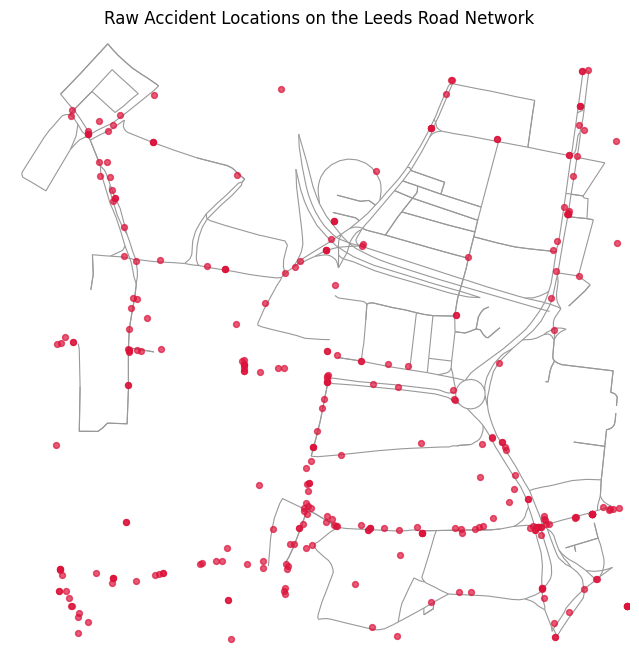

In [25]:
# Reproject accidents to the same CRS as the projected road network
study_accidents_proj = study_accidents.to_crs(edges_gdf.crs)

fig, ax = ox.plot_graph(
    G_proj,
    node_size=0,
    edge_linewidth=0.8,
    bgcolor="white",
    show=False,
    close=False
)

study_accidents_proj.plot(ax=ax, color="crimson", markersize=18, alpha=0.7)
ax.set_title("Raw Accident Locations on the Leeds Road Network")
plt.show()

The plot shows the observed accident locations relative to the study-area road network. Even at this stage, the accidents do not appear uniformly spread across the network, which motivates the more formal clustering and autocorrelation analysis below.

Step 5: Snap accident points to their nearest road segment

The Topic 6 materials explicitly discuss snapping points to the network before carrying out point-pattern analysis in network space. This matters here because accident coordinates may not fall exactly on the road centreline geometry due to recording precision, map generalisation, or the fact that real roads have width while the network is represented as a line. 

The nearest road segment is found for each accident, and the exact projected position along that segment is recorded. These snapped locations are then used for Questions 2 and 3.

In [27]:
# Reproject accidents to match road-network CRS
study_accidents_proj = study_accidents.to_crs(edges_gdf.crs).copy()

# Prepare edge dataframe with non-conflicting names
edges_for_join = edges_gdf[["edge_id", "u", "v", "length", "geometry"]].copy()
edges_for_join = edges_for_join.rename(columns={"length": "edge_length"})

# Snap accidents to nearest road segment
acc_snap = gpd.sjoin_nearest(
    study_accidents_proj[["accident_id", "geometry"]],
    edges_for_join,
    how="left",
    distance_col="snap_dist"
)

# After join, geometry is still the accident geometry.
# Bring edge geometry in explicitly by merge to avoid ambiguity.
acc_snap = acc_snap.merge(
    edges_for_join[["edge_id", "edge_length", "geometry"]].rename(columns={"geometry": "edge_geom"}),
    on=["edge_id", "edge_length"],
    how="left"
)

# Position of accident along matched edge
acc_snap["edge_pos_m"] = acc_snap.apply(
    lambda r: r["edge_geom"].project(r["geometry"]),
    axis=1
)

# Fraction along road segment
acc_snap["edge_frac"] = acc_snap["edge_pos_m"] / acc_snap["edge_length"]

# Snapped point on edge
acc_snap["snapped_geom"] = acc_snap.apply(
    lambda r: r["edge_geom"].interpolate(r["edge_pos_m"]),
    axis=1
)

# Distance from nearest intersection as fraction of segment length
acc_snap["nearest_intersection_frac"] = np.minimum(
    acc_snap["edge_frac"],
    1 - acc_snap["edge_frac"]
)

acc_snap_gdf = gpd.GeoDataFrame(acc_snap, geometry="snapped_geom", crs=edges_gdf.crs)

acc_snap_gdf.head()

,accident_id,geometry,index_right,edge_id,u,v,edge_length,snap_dist,edge_geom,edge_pos_m,edge_frac,snapped_geom,nearest_intersection_frac
0,0,POINT (596139.594 5961898.965),221,221,9755805559,10563335063,99.790328,1.587579,"LINESTRING (596102.682 5961813.847, 596104.091...",92.901892,0.930971,POINT (596138.117 5961899.545),0.069029
1,1,POINT (595828.512 5962184.633),214,214,9405615106,921265743,300.821304,1.785745,"LINESTRING (595741.861 5962123.206, 595740.475...",294.000051,0.977325,POINT (595826.726 5962184.644),0.022675
2,2,POINT (596400.985 5961874.642),234,234,5728993698,10563335054,111.651281,3.299612,"LINESTRING (596479.595 5961873.449, 596461.763...",78.623440,0.704188,POINT (596401.042 5961871.343),0.295812
3,3,POINT (596474.371 5962557.794),143,143,304904880,3071035464,101.566891,3.545053,"LINESTRING (596476.751 5962553.726, 596425.615...",3.105646,0.030577,POINT (596473.701 5962554.312),0.030577
4,4,POINT (596474.371 5962557.794),143,143,304904880,3071035464,101.566891,3.545053,"LINESTRING (596476.751 5962553.726, 596425.615...",3.105646,0.030577,POINT (596473.701 5962554.312),0.030577


In [28]:
print("study_accidents CRS:", study_accidents.crs)
print("edges_gdf CRS:", edges_gdf.crs)
print(edges_gdf.columns.tolist())

study_accidents CRS: EPSG:27700
edges_gdf CRS: EPSG:32630
['u', 'v', 'key', 'osmid', 'highway', 'lanes', 'maxspeed', 'name', 'oneway', 'ref', 'reversed', 'length', 'from', 'to', 'geometry', 'junction', 'access', 'tunnel', 'bridge', 'edge_id']


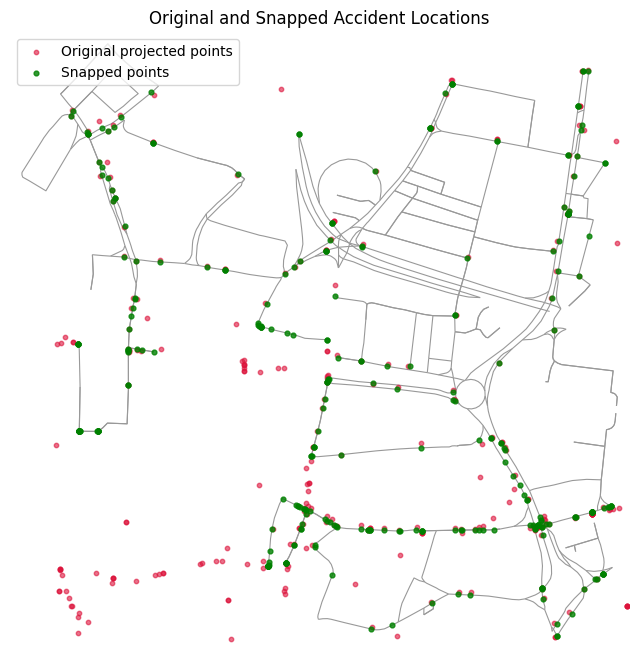

In [40]:
fig, ax = ox.plot_graph(
    G_proj,
    node_size=0,
    edge_linewidth=0.8,
    bgcolor="white",
    show=False,
    close=False
)

study_accidents_proj.plot(ax=ax, color="crimson", markersize=10, alpha=0.6, label="Original projected points")
acc_snap_gdf.plot(ax=ax, color="green", markersize=12, alpha=0.8, label="Snapped points")

ax.set_title("Original and Snapped Accident Locations")
ax.legend()
plt.show()

The snapped points lie directly on the road geometries, making them suitable for network-space analysis. This is the appropriate representation for later calculations, because both the K-function and the segment-based Moran’s I are defined relative to the network rather than unrestricted planar space. 

Step 6: Count accidents per road segment

To investigate whether accident-heavy roads tend to connect to other accident-heavy roads, we first need an edge-level attribute. Following the Topic 6 lecture logic, the number of snapped events on each road segment is used as the segment’s value. This turns the road network into a spatial graph whose edges carry accident counts. 

In [41]:
edge_counts = acc_snap_gdf.groupby("edge_id").size().rename("acc_count")

edges_gdf = edges_gdf.merge(edge_counts, on="edge_id", how="left")
edges_gdf["acc_count"] = edges_gdf["acc_count"].fillna(0).astype(int)

edges_gdf[["edge_id", "acc_count"]].head()

,edge_id,acc_count
0,0,0
1,1,0
2,2,0
3,3,0
4,4,1


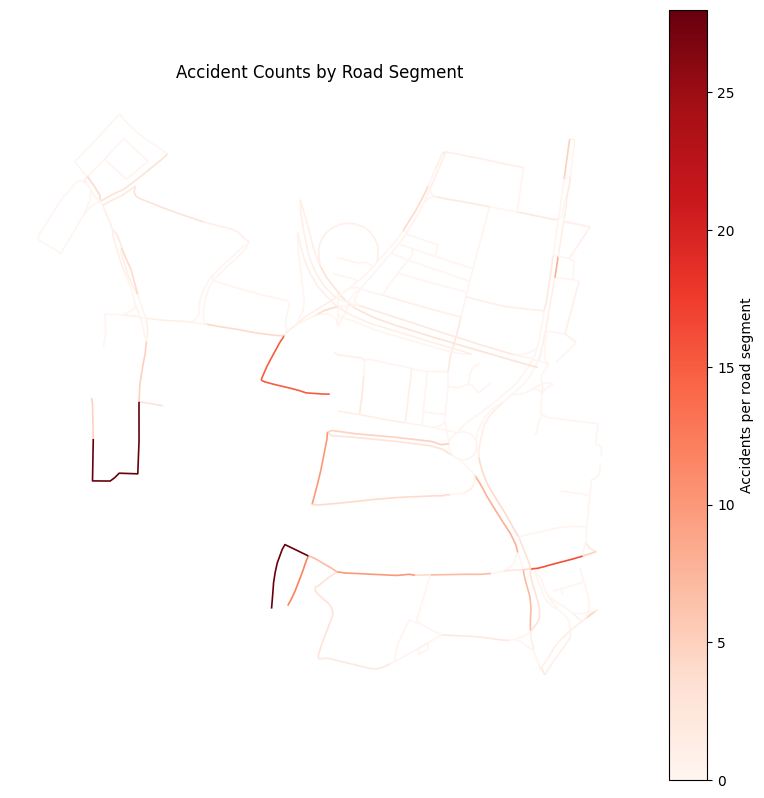

In [51]:
fig, ax = plt.subplots(figsize=(10, 10))
edges_gdf.plot(
    ax=ax,
    column="acc_count",
    cmap="Reds",
    linewidth=1.2,
    legend=True,
    legend_kwds={"label": "Accidents per road segment"}
)
ax.set_title("Accident Counts by Road Segment")
ax.set_axis_off()
plt.show()

This road-segment map is already informative: it makes visible whether accidents are concentrated on a few specific road segments or spread more evenly across the network. However, visual appearance alone can be misleading, so a formal autocorrelation measure is needed. The Topic 6 lecture explicitly warns that maps can be deceptive and motivates the use of spatial autocorrelation statistics such as Moran’s I. 

Step 7: Compute Moran’s I for road-segment accident counts

The Topic 6 materials describe spatial network autocorrelation in exactly the form needed here:

1. snap points to network edges,
2. count the number of points on each edge,
3. define spatial weights using the edge adjacency matrix,
4. calculate Moran’s I on those edge counts. 

Here, two road segments are considered neighbours if they share a node (that is, if they are directly connected in the road graph).

In [52]:
# Build edge-neighbour dictionary from shared endpoints
node_to_edges = defaultdict(set)

for _, row in edges_gdf.iterrows():
    node_to_edges[row["u"]].add(row["edge_id"])
    node_to_edges[row["v"]].add(row["edge_id"])

neighbors = {eid: set() for eid in edges_gdf["edge_id"]}

for eids in node_to_edges.values():
    for eid in eids:
        neighbors[eid].update(eids - {eid})

neighbors = {k: sorted(v) for k, v in neighbors.items()}

# Spatial weights
w = W(neighbors, silence_warnings=True)
w.transform = "R"

# Align values with weight ordering
edge_values = edges_gdf.set_index("edge_id").loc[w.id_order, "acc_count"].values

# Moran's I
moran = Moran(edge_values, w, permutations=999)

print("Moran's I:", moran.I)
print("Expected I under randomness:", moran.EI)
print("p-value (permutation):", moran.p_sim)
print("z-score:", moran.z_sim)

Moran's I: 0.3595879326256184
Expected I under randomness: -0.0035460992907801418
p-value (permutation): 0.001
z-score: 9.330201564011523


Moran’s I measures whether connected road segments tend to have similar accident counts. A positive value indicates that high-count roads are adjacent to other high-count roads (and low-count roads to low-count roads), whereas a near-zero value would suggest no meaningful edge-level spatial autocorrelation. The sign, magnitude, and permutation p-value together determine whether this pattern is strong and statistically meaningful. 